# Where cells sit in the cycle

A knockout that stalls the cell cycle leaves its mark in the DNA content of its cells. This tutorial places single
cells on the cycle from their DNA stain with {func}`~mantispy.tl.fit_cell_cycle` and
{func}`~mantispy.tl.project_cell_cycle`, and reads the result for knockouts whose effect on the cycle is known.

The cells come from an optical pooled CRISPR screen in HeLa cells ({func}`~mantispy.ds.aconcagua`), eight genes and
the non-targeting controls, all imaged with a DAPI stain. Each gene's function predicts a place in the cycle, so we
state the predictions before looking:

| Gene | Function | Prediction |
| --- | --- | --- |
| RRM1 | makes the nucleotides DNA replication needs | more cells in S |
| HAUS6, SKA2 | build and attach the mitotic spindle | more cells in G2M |
| DTL | stops DNA from being copied twice | more cells above 4N, off the cycle |
| PSMB7, SF3B3 | proteasome and spliceosome, needed to pass through mitosis | more cells in G2M |
| ITGAV, TLN1 | cell adhesion, no cell-cycle role | the same as the controls |

The [optical pooled screens case study](../../case_studies/optical_pooled_screens.ipynb) puts these genes in the
context of the whole screen.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import mantispy as mt

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

cells = mt.ds.aconcagua(cells=True)
cells.obs["Metadata_Gene"].value_counts().rename("cells").to_frame().T

Metadata_Gene,nontargeting,TLN1,SF3B3,HAUS6,ITGAV,PSMB7,RRM1,DTL,SKA2
cells,24166,2049,1984,1969,1921,1903,1890,1830,962


## DNA content

{func}`~mantispy.tl.dna_content` turns the integrated DAPI intensity into doublings of the G1 peak, so a 2N nucleus
sits near 0 and a 4N nucleus near 1. Staining differs between wells, so the G1 peak is found per well. In a pooled
screen every well also holds non-targeting cells, and ``reference="negcon"`` finds the peak on those alone. A
knockout that empties G1 then cannot pull the peak of its well away.

In [2]:
mt.tl.dna_content(
    cells,
    dna_feature="Nuclei_Intensity_IntegratedIntensity_DAPI",
    by=("Metadata_Plate", "Metadata_Well"),
    reference="negcon",
)

## Fitting the clock

{func}`~mantispy.tl.fit_cell_cycle` fits the clock on the non-targeting cells. It first checks that they cycle: a
2N peak, a separate 4N peak and S cells between them. It then orders the cells G1, S and G2M by DNA content and
turns each cell's cumulative share into a position in the cycle, corrected for the age distribution of a growing
population. Position 0 is the start of G1 and 1 is division. DNA content cannot tell a cell in mitosis from one in
G2, since both hold 4N, so the two share one phase.

The model lands in ``uns["mantispy"]["cell_cycle"]``: the ``gate`` report of the check, the controls' ``fractions``
in G1, S and G2M, the width ``sd`` of their 2N peak and the ``off_cycle`` DNA bounds beyond which a cell has no
place on the cycle.

In [3]:
mt.tl.fit_cell_cycle(cells, reference="negcon")
model = cells.uns["mantispy"]["cell_cycle"]
print("control shares of G1, S and G2M:", np.round(model["fractions"], 3))
print("off-cycle bounds:", np.round(model["off_cycle"], 2))
pd.Series(model["gate"]).round(3)

control shares of G1, S and G2M: [0.726 0.143 0.131]
off-cycle bounds: [-0.39  1.31]


peak_4n          0.92
peak_ratio      0.198
valley_ratio    0.519
s_floor         0.519
s_share         0.142
passed              1
dtype: object

## Placing every cell

{func}`~mantispy.tl.project_cell_cycle` places every cell, knockouts included, on the controls' clock. Each cell
gets a posterior over its position, the age distribution of the controls times how well its DNA content fits each
position, and four outputs:

- ``obs["cell_cycle_phase"]``: G1, S, G2M, or off-cycle for a cell outside the controls' DNA range;
- ``obs["cell_cycle_position"]``: the posterior median;
- ``obsm["cell_cycle_quantiles"]``: the 5%, 25%, 50%, 75% and 95% posterior quantiles;
- ``obs["cell_cycle_well_shift"]``: how far the 2N and 4N peaks of the cell's well both sit off the controls',
  in doublings.

The last one is a check on the measurement. A well whose two peaks sit off by the same amount reads its DNA stain
differently, and every position in it carries that shift; a warning names such wells.

In [4]:
mt.tl.project_cell_cycle(cells)
quantiles = pd.DataFrame(
    cells.obsm["cell_cycle_quantiles"], index=cells.obs_names, columns=["5%", "25%", "50%", "75%", "95%"]
)
example = cells.obs.groupby("cell_cycle_phase", observed=True).head(1).index
pd.concat([cells.obs.loc[example, ["Metadata_DNAContent", "cell_cycle_phase"]], quantiles.loc[example]], axis=1).round(
    2
)

,Metadata_DNAContent,cell_cycle_phase,5%,25%,50%,75%,95%
0,0.14,G1,0.03,0.16,0.34,0.54,0.62
3,1.00,G2M,0.84,0.88,0.92,0.96,0.99
4,0.40,S,0.62,0.65,0.68,0.70,0.73
5,1.45,off-cycle,NaN,NaN,NaN,NaN,NaN


An S cell gets a narrow interval, because its DNA content says how far replication has gone. A G1 or G2M cell
gets its whole plateau, because DNA content does not order cells within it. An off-cycle cell gets no position.

The histogram of the controls shows the phases over the DNA content.

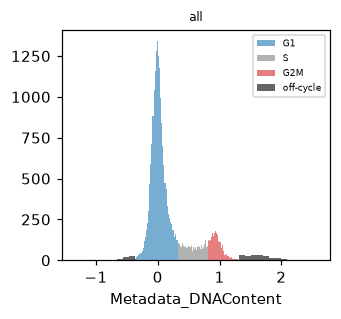

In [5]:
controls = cells[cells.obs["Metadata_Control_Type"] == "negcon"]
mt.pl.cell_cycle(controls, dna_feature="Metadata_DNAContent", key="cell_cycle_phase", by=None)

## Phases by gene

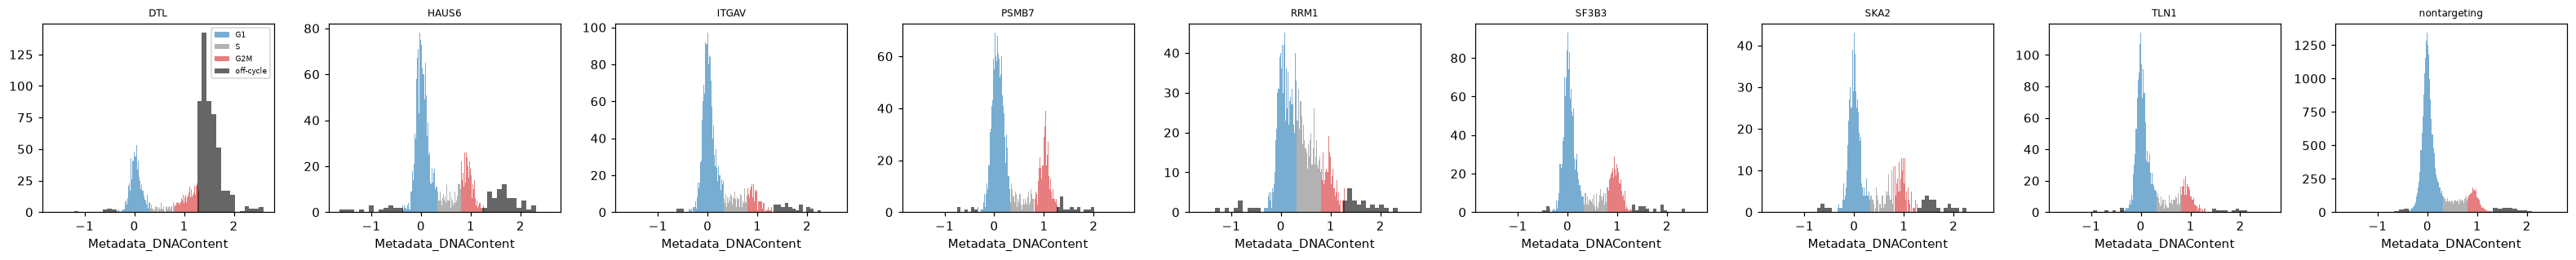

In [6]:
mt.pl.cell_cycle(cells, dna_feature="Metadata_DNAContent", key="cell_cycle_phase", by="Metadata_Gene")

With ``position=``, {func}`~mantispy.pl.cell_cycle` draws how each gene's cells occupy the cycle instead. Each
cell adds one position drawn from its own interval, so a G1 cell spreads over G1 rather than stacking on its median.

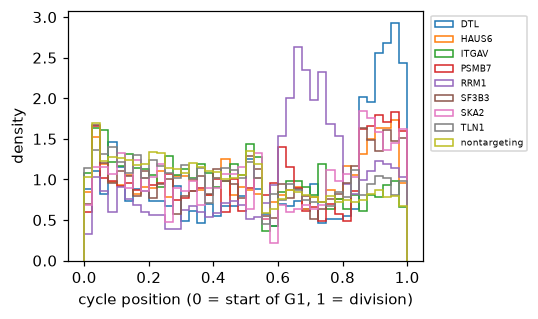

In [7]:
mt.pl.cell_cycle(cells, position="cell_cycle", by="Metadata_Gene")

## Checking the predictions

The table gives each gene's share of cells per phase minus the controls' share, with the off-cycle cells split into
those below 2N and those above 4N. Each prediction becomes a rule on it, with a change of 0.05 (five percentage
points of cells) as the smallest one that counts.

In [8]:
obs = cells.obs
low, high = model["off_cycle"]
phase = obs["cell_cycle_phase"].astype(str).where(obs["cell_cycle_phase"] != "off-cycle", "")
phase[obs["Metadata_DNAContent"] < low] = "below 2N"
phase[obs["Metadata_DNAContent"] > high] = "above 4N"
share = pd.crosstab(obs["Metadata_Gene"], phase, normalize="index")[["G1", "S", "G2M", "below 2N", "above 4N"]]
change = (share - share.loc["nontargeting"]).drop(index="nontargeting")

rules = {
    "RRM1": ("S up", lambda c: c["S"] > 0.05),
    "HAUS6": ("G2M up", lambda c: c["G2M"] > 0.05),
    "SKA2": ("G2M up", lambda c: c["G2M"] > 0.05),
    "DTL": ("above 4N up", lambda c: c["above 4N"] > 0.05),
    "PSMB7": ("G2M up", lambda c: c["G2M"] > 0.05),
    "SF3B3": ("G2M up", lambda c: c["G2M"] > 0.05),
    "ITGAV": ("no phase moves", lambda c: (c[["G1", "S", "G2M"]].abs() <= 0.05).all()),
    "TLN1": ("no phase moves", lambda c: (c[["G1", "S", "G2M"]].abs() <= 0.05).all()),
}
change.loc[list(rules)].round(3).assign(
    prediction=[rule for rule, _ in rules.values()],
    holds=[bool(test(change.loc[gene])) for gene, (_, test) in rules.items()],
)

cell_cycle_phase,G1,S,G2M,below 2N,above 4N,prediction,holds
Metadata_Gene,,,,,,,
RRM1,-0.265,0.222,0.036,0.002,0.005,S up,True
HAUS6,-0.135,0.000,0.106,0.006,0.023,G2M up,True
SKA2,-0.148,0.012,0.120,0.002,0.014,G2M up,True
DTL,-0.349,-0.061,0.137,0.002,0.271,above 4N up,True
PSMB7,-0.116,-0.028,0.141,0.000,0.002,G2M up,True
SF3B3,-0.116,-0.009,0.123,-0.001,0.003,G2M up,True
ITGAV,-0.013,0.004,0.002,-0.001,0.009,no phase moves,True
TLN1,-0.028,-0.000,0.031,0.000,-0.003,no phase moves,True


All eight predictions hold. RRM1 gains 22 points of its cells in S. The spindle genes HAUS6 and SKA2 gain 11
and 12 points in G2M, and PSMB7 and SF3B3 gain 14 and 12. DTL gains 27 points above 4N, consistent with the
re-replication its loss is known to cause, and 14 in G2M. ITGAV and TLN1 move no phase by more than about 3 points.

## How sure is a shift?

Cells of one guide are not independent replicates of a knockout: the guide, its efficiency and the wells it landed in
are shared. So the uncertainty of a gene's shift comes from resampling its guides, and each cell's own uncertainty
enters by drawing its position from its interval, as the occupancy plot does. The number is the shift in mean cycle
position against the controls, positive for cells that sit later in the cycle.

In [9]:
levels = np.array([0.05, 0.25, 0.5, 0.75, 0.95])
placed = np.isfinite(obs["cell_cycle_position"].to_numpy())
q = cells.obsm["cell_cycle_quantiles"][placed]
guide = obs.loc[placed, "Metadata_Guide"].astype(str).to_numpy()
gene_of = obs.loc[placed].groupby("Metadata_Guide", observed=True)["Metadata_Gene"].first().astype(str)
rows_of = {g: np.flatnonzero(guide == g) for g in gene_of.index}
rng = np.random.default_rng(0)


def draw(rows):
    """One position per cell, interpolated between its reported quantiles."""
    u = rng.random(rows.size)
    upper = np.clip(np.searchsorted(levels, u), 1, levels.size - 1)
    t = np.clip((u - levels[upper - 1]) / (levels[upper] - levels[upper - 1]), 0, 1)
    return q[rows, upper - 1] + t * (q[rows, upper] - q[rows, upper - 1])


def resampled_shift(gene, n=200):
    """Shift of a gene's mean position against the controls' over resampled guides and drawn positions."""
    guides = {name: gene_of.index[gene_of == name].to_numpy() for name in (gene, "nontargeting")}
    shifts = []
    for _ in range(n):
        means = [
            draw(np.concatenate([rows_of[g] for g in rng.choice(guides[name], guides[name].size)])).mean()
            for name in (gene, "nontargeting")
        ]
        shifts.append(means[0] - means[1])
    return np.mean(shifts), *np.percentile(shifts, [2.5, 97.5])


genes = list(rules)
pd.DataFrame([resampled_shift(gene) for gene in genes], index=genes, columns=["shift", "2.5%", "97.5%"]).round(3)

,shift,2.5%,97.5%
RRM1,0.146,0.123,0.173
HAUS6,0.079,0.032,0.139
SKA2,0.088,0.063,0.118
DTL,0.144,0.091,0.200
PSMB7,0.097,0.059,0.146
SF3B3,0.091,0.024,0.158
ITGAV,0.009,-0.005,0.023
TLN1,0.021,-0.002,0.039


The six knockouts with a cycle phenotype sit 0.08 to 0.15 of a cycle later than the controls, and none of
their intervals includes 0. The intervals of ITGAV and TLN1 do. Off-cycle cells have no position, so DTL's cells
above 4N do not enter its shift.

## The well check

In [10]:
well = obs.groupby(["Metadata_Plate", "Metadata_Well"], observed=True)["cell_cycle_well_shift"].first()
print(f"{well.notna().sum()} of {well.size} wells checked; the 2N peak width is {model['sd']:.3f} doublings")
well.describe().round(3)

42 of 46 wells checked; the 2N peak width is 0.096 doublings


count    42.000
mean     -0.008
std       0.024
min      -0.076
25%      -0.020
50%      -0.008
75%       0.007
max       0.052
Name: cell_cycle_well_shift, dtype: float64

The check judged 42 of the 46 wells. The other four have no shift, because one of their peaks is missing or the
two disagree. No judged well is off by more than the 2N peak width, the largest shift being 0.076 doublings, so no
warning was raised. That is expected here, since {func}`~mantispy.tl.dna_content` found each well's G1 peak on its
own non-targeting cells. With ``by="Metadata_Plate"`` instead, a well that stains differently from the rest of its
plate would show up in this check.